# Stage-Two Filamentary Coil Optimization
This notebook will show how to use DESC to perform stage two coil optimization with filamentary coils of differing parameterizations, such as Fourier in terms of arbitrary angle (as pioneered by [FOCUS][1]) or planar coils described in terms of the coil center, normal to the plane, and a Fourier series describing the radius of the coil in that plane. We will first find a coilset for the precise QA ([Landreman & Paul 2022][2]) vacuum equilibrium, starting from an initial coilset composed of circular planar coils, with only coils parameterized by a Fourier series in an arbitrary curve parameter. A second coil optimization will be performed for a W7-X-like finite beta equilibrium using a coilset composed of various coil parameterizations. Once optimized, the normal field error will be assessed, and for the vacuum equilibrium, field line tracing will be performed to compare the Poincare trace to the equilibrium flux surfaces.


[1]: <https://doi.org/10.1088/1741-4326/aa8e0a> "Zhu, C., Hudson, S. R., Song, Y. & Wan, Y. New method to design stellarator coils without the winding surface. Nucl. Fusion 58, 016008 (2018)."

[2]: <https://journals.aps.org/prl/abstract/10.1103/PhysRevLett.128.035001> "M. Landreman. & E. Paul. 2022 Physical Review Letters"

In [1]:
import sys
import os

sys.path.insert(0, os.path.abspath("."))
sys.path.append(os.path.abspath("../../../"))

In [2]:
from desc import set_device
set_device("gpu")

As mentioned in [DESC Documentation on performance tips](https://desc-docs.readthedocs.io/en/latest/performance_tips.html), one can use compilation cache directory to reduce the compilation overhead time. Uncomment the next code block to take advantage of the cache.

Note: One needs to create jax-caches folder manually.

In [3]:
import jax

jax.config.update("jax_compilation_cache_dir", "../jax-caches")
jax.config.update("jax_persistent_cache_min_entry_size_bytes", -1)
jax.config.update("jax_persistent_cache_min_compile_time_secs", 0)

In [4]:
import numpy as np
from desc.coils import (
    CoilSet,
    FourierPlanarCoil,
    MixedCoilSet,
    initialize_modular_coils,
    initialize_saddle_coils,
)
import desc.examples
from desc.equilibrium import Equilibrium
from desc.plotting import plot_2d, plot_3d, plot_coils, plot_comparison
from desc.grid import LinearGrid
from desc.objectives import (
    ObjectiveFunction,
    CoilCurvature,
    CoilLength,
    CoilTorsion,
    CoilSetLinkingNumber,
    CoilSetMinDistance,
    PlasmaCoilSetMinDistance,
    QuadraticFlux,
    ToroidalFlux,
    FixSumCoilCurrent,
    FixParameters,
)
from desc.optimize import Optimizer
from desc.integrals import compute_B_plasma
import time
import plotly.express as px
import plotly.io as pio
from desc.io import load
# This ensures Plotly output works in multiple places:
# plotly_mimetype: VS Code notebook UI
# notebook: "Jupyter: Export to HTML" command in VS Code
# See https://plotly.com/python/renderers/#multiple-renderers
pio.renderers.default = "plotly_mimetype+notebook"

/pscratch/sd/r/rgaur/DESC2/DESC/desc/integrals/_interp_utils.py:19: UserWarning: 
jax-finufft is not installed.
If you want to use NUFFTs, follow the DESC installation instructions.
Otherwise you must set the parameter nufft_eps to zero
when computing effective ripple, Gamma_c, and any other
computations that involve bounce integrals.

  warnings.warn(


## Coil Optimization Metrics

Two main figures of merit regarding the quality of the coil optimization in recreating the equilibrium are the average normalized magnetic field and Poincare plot from the coils. The average normalized magnetic field is a measure of how well the coils' field (plus the plasma field if it is finite beta) recreates last closed flux surface of the target equilibrium and is given as 
$$
\frac{\left<|\mathbf{B}_{\text{total}}\cdot \mathbf{\hat{n}}|\right>}{\left<|\mathbf{B}_{\text{total}}|\right>}
$$
where $\mathbf{\hat{n}}$ is the normal vector to the equilibrium's last closed flux surface and $\mathbf{B}_{\text{total}} = \mathbf{B}_{\text{coils}} + \mathbf{B}_{\text{plasma currents}}$. Field traces are also significant for vacuum equilibria because they visually show the quality of the coil field in recreating the equilibrium vacuum flux surfaces.

These two metrics are calculated in functions below.

In [5]:
def compute_average_normalized_field(
    field, eq, vacuum=False, chunk_size=None, B_plasma_chunk_size=None
):
    if B_plasma_chunk_size is None:
        B_plasma_chunk_size = chunk_size
    grid = LinearGrid(M=80, N=80, NFP=eq.NFP)
    if vacuum:
        # we can avoid the expensive plasma contribution calculation if we
        # just pass in the surface instead of the Equilibrium!
        Bn, surf_coords = field.compute_Bnormal(
            eq.surface,
            eval_grid=grid,
            chunk_size=chunk_size,
            B_plasma_chunk_size=B_plasma_chunk_size,
        )
    else:
        Bn, surf_coords = field.compute_Bnormal(
            eq,
            eval_grid=grid,
            chunk_size=chunk_size,
            B_plasma_chunk_size=B_plasma_chunk_size,
        )
    normalizing_field_vec = field.compute_magnetic_field(surf_coords)
    if not vacuum:
        # add plasma field to the normalizing field
        normalizing_field_vec += compute_B_plasma(
            eq, eval_grid=grid, chunk_size=B_plasma_chunk_size
        )
    normalizing_field = np.mean(np.linalg.norm(normalizing_field_vec, axis=1))
    return np.mean(np.abs(Bn)) / normalizing_field


def plot_field_lines(field, eq):
    # for starting locations we'll pick positions on flux surfaces on the outboard midplane
    grid_trace = LinearGrid(rho=np.linspace(0, 1, 9))
    r0 = eq.compute("R", grid=grid_trace)["R"]
    z0 = eq.compute("Z", grid=grid_trace)["Z"]
    fig, ax = desc.plotting.plot_surfaces(eq)
    fig, ax = desc.plotting.poincare_plot(
        field,
        r0,
        z0,
        NFP=eq.NFP,
        ax=ax,
        color="k",
        size=1,
    )
    return fig, ax

## Vacuum

We will be focusing on optimizing coils with the vacuum precise QA as the target equilibrium.

In [6]:
eq = load("eq_NFP3_A+10.0_tor+0.0_mr+0.30_shift+0.00_wd+0.00_elong+1.50_wellwt+2.0_vacuum_final2_resolve.h5")

In [7]:
grid_trace = LinearGrid(rho=np.linspace(0, 1, 18))
#fig, ax = desc.plotting.plot_surfaces(eq, figsize=(40, 40))
eq.compute("iota", grid=grid_trace)["iota"]

Array([0.72520726, 0.72522365, 0.72526815, 0.72532745, 0.72538147,
       0.72540626, 0.7253776 , 0.72527468, 0.72508359, 0.72480005,
       0.72443121, 0.72399625, 0.72352593, 0.72306105, 0.72264898,
       0.72233569, 0.72214618, 0.72203781], dtype=float64)

## Using REGCOIL Algorithm for initial guess

Instead of starting from a circular coilset, we can do a sort of "warm-start" by first solving a simpler problem where we find a surface current on an exterior surface which minimizes the normal field error. This problem can be quickly solved as a regularized least-squares problem ([See the REGCOIL tutorial notebook for more info](./coil_optimization_REGCOIL.ipynb)), which can give an initial guess coilset which has low Bn from which to further refine with filamentary coil optimization.

In [27]:
from desc.magnetic_fields import (
    solve_regularized_surface_current,
    FourierCurrentPotentialField,
)
from scipy.constants import mu_0
eq=eq.copy()
# First, make a constant-offset surface upon which our surface current will lie.
surf = eq.surface.constant_offset_surface(
    offset=0.1,  # desired offset (m)
    M=14,  # Poloidal resolution of desired offset surface
    N=eq.N,  # Toroidal resolution of desired offset surface
    grid=LinearGrid(M=26, N =2* eq.N, NFP=eq.NFP),
)

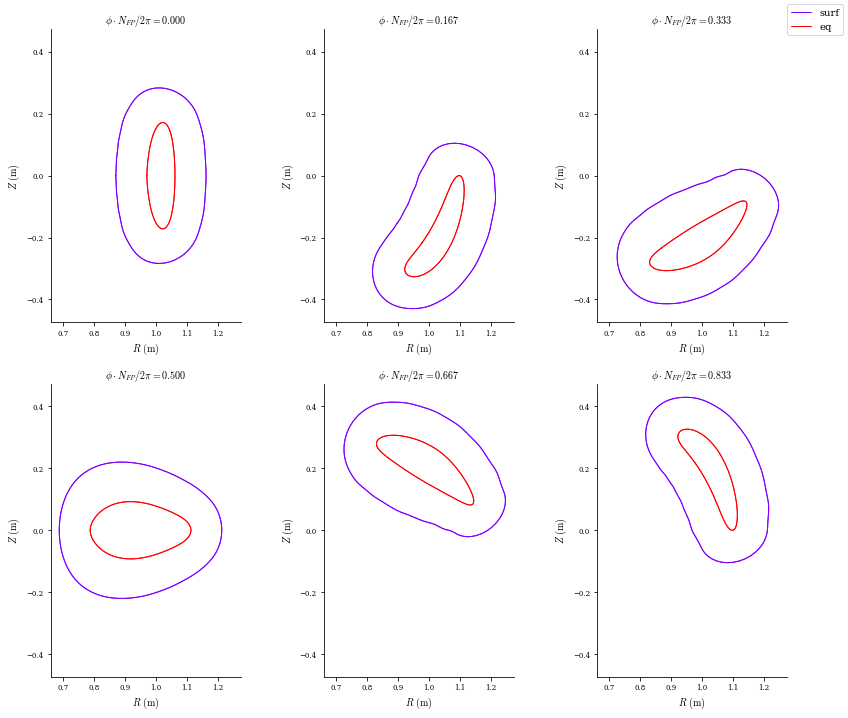

In [28]:
plot_comparison([surf, eq], labels=["surf", "eq"], theta=0, rho=np.array(1.0));

In [29]:
# create the FourierCurrentPotentialField object from the constant offset surface we found in the previous cell
surface_current_field = FourierCurrentPotentialField.from_surface(
    surf,
    I=0,
    # manually setting G to value needed to provide the equilibrium's toroidal flux,
    # though this is not necessary as it gets set automatically inside the solve_regularized_surface_current function
    G=np.asarray(
        [
            -eq.compute("G", grid=LinearGrid(rho=np.array(1.0)))["G"][0]
            / mu_0
            * 2
            * np.pi
        ]
    ),
    # set symmetry of the current potential, "sin" is usually expected for stellarator-symmetric surfaces and equilibria
    sym_Phi=False,
)

surface_current_field.change_Phi_resolution(M=30, N=18)

lambda_regularization = np.append(np.array([0]), np.logspace(-30, -10, 30))

# solve_regularized_surface_current method runs the REGCOIL algorithm
fields, data = solve_regularized_surface_current(
    surface_current_field,  # the surface current field whose geometry and Phi resolution will be used
    eq=eq,  # the Equilibrium object to minimize Bn on the surface of
    current_helicity=(
        1,
        0,
    ),  # pair of integers (M_coil. N_coil), determines topology of contours (almost like  QS helicity),
    #  M_coil is the number of times the coil transits poloidally before closing back on itself
    # and N_coil is the toroidal analog (if M_coil!=0 and N_coil=0, we have modular coils, if both M_coil
    # and N_coil are nonzero, we have helical coils)
    # we pass in an array to perform scan over the regularization parameter (which we call lambda_regularization)
    # to see tradeoff between Bn and current complexity
    eval_grid=LinearGrid(N=30, M=60, NFP=eq.NFP, sym=False),
    source_grid=LinearGrid(N=35, M=35, NFP=eq.NFP),
    lambda_regularization=lambda_regularization,
    chunk_size=1,
    regularization_type="simple",
    # lambda_regularization determines the complexity of the coils, larger values yield simpler coils at the cost of higher Bn error
    vacuum=True,  # this is a vacuum equilibrium, so no need to calculate the Bn contribution from the plasma currents
)

# solve_regularized_surface_current returns a list of FourierCurrentPotentialField objects, one for each lambda, even if a single lambda is passed in
surface_current_field = fields[0]

##########################################################
Calculating Phi_SV for lambda_regularization = 0.00000e+00
##########################################################
chi^2 B = 5.18873e-10
min Bnormal = 2.33633e-12 (T)
Max Bnormal = 6.69277e-08 (T)
Avg Bnormal = 4.54370e-09 (T)
min Bnormal = 1.90739e-12 (unitless)
Max Bnormal = 5.46402e-08 (unitless)
Avg Bnormal = 3.70951e-09 (unitless)
##########################################################
Calculating Phi_SV for lambda_regularization = 1.00000e-30
##########################################################
chi^2 B = 4.75157e-10
min Bnormal = 2.29529e-18 (T)
Max Bnormal = 6.77854e-08 (T)
Avg Bnormal = 4.13086e-09 (T)
min Bnormal = 1.87389e-18 (unitless)
Max Bnormal = 5.53404e-08 (unitless)
Avg Bnormal = 3.37246e-09 (unitless)
##########################################################
Calculating Phi_SV for lambda_regularization = 4.89390e-30
##########################################################
chi^2 B = 4.78136e-10
m

In [30]:
## import numpy as np
import matplotlib.pyplot as plt

from desc.equilibrium import Equilibrium
from desc.geometry import FourierRZToroidalSurface
from desc.grid import LinearGrid
from desc.io import load
from desc.objectives import (
    FixParameters,
    ObjectiveFunction,
    QuadraticFlux,
    SurfaceCurrentRegularization,
)
from desc.optimize import Optimizer
from scipy.constants import mu_0
from desc.magnetic_fields import (
    FourierCurrentPotentialField,
    solve_regularized_surface_current,
)

from desc.examples import get
from desc.plotting import (
    plot_comparison,
    plot_surfaces,
    plot_3d,
    plot_coils,
    plot_2d,
    poincare_plot,
)
import plotly.express as px
import plotly.io as pio

# This ensures Plotly output works in multiple places:
# plotly_mimetype: VS Code notebook UI
# notebook: "Jupyter: Export to HTML" command in VS Code
# See https://plotly.com/python/renderers/#multiple-renderers
pio.renderers.default = "plotly_mimetype+notebook"
# define utility function
def plot_field_lines(field, eq):
    # for starting locations we'll pick positions on flux surfaces on the outboard midplane
    grid_trace = LinearGrid(rho=np.linspace(0, 1, 9))
    r0 = eq.compute("R", grid=grid_trace)["R"]
    z0 = eq.compute("Z", grid=grid_trace)["Z"]
    fig, ax = plot_surfaces(eq)
    fig, ax = poincare_plot(
        field,
        r0,
        z0,
        NFP=eq.NFP,
        ax=ax,
        color="k",
        size=1,
    )
    return fig, ax


# plotting utility functions
def plot_regcoil_outputs(
    field,
    data,
    eq,
    eval_grid=None,
    source_grid=None,
    return_data=False,
    vacuum=False,
    **kwargs,
):
    try:
        # if it is a list, just grab the first one
        # as we change the attribute anyways so just need the correct
        # geometry
        field = field[0]
    except TypeError:
        # it was not a list, so proceed as usual
        pass
    cmap = kwargs.pop("cmap", "viridis")
    field = (
        field.copy()
    )  # copy the field so that we are not changing the passed-in field
    scan = len(data["Phi_mn"]) > 1
    scan_str = "_scan" if scan else ""

    lambdas = data["lambda_regularization"]
    chi2Bs = data["chi^2_B"]
    chi2Ks = data["chi^2_K"]
    phi_mns = data["Phi_mn"]
    if eval_grid is None:
        eval_grid = data["eval_grid"]
        eval_grid = (
            eval_grid
            if (not eval_grid.sym and eval_grid.N != 0)
            else LinearGrid(
                M=eval_grid.M,
                N=max(eval_grid.N, 1),
                sym=False,
                NFP=eval_grid.NFP,
                endpoint=True,
            )
        )
    if source_grid is None:
        source_grid = data["source_grid"]

    # check if we can use existing quantities in data
    # or re-evaluate based off of the new grids passed-in
    recalc_eval_grid_quantites = not eval_grid.equiv(
        data["eval_grid"]
    ) or not source_grid.equiv(data["source_grid"])

    if "external_field" in data.keys() and recalc_eval_grid_quantites:
        external_field = data["external_field"]
    else:
        external_field = None

    ncontours = kwargs.pop("ncontours", 15)
    markersize = kwargs.pop("markersize", None)
    xlabel_fontsize = kwargs.pop("xlabel_fontsize", None)
    ylabel_fontsize = kwargs.pop("ylabel_fontsize", None)
    title_fontsize = kwargs.pop("title_fontsize", None)

    figdata = {}
    axdata = {}
    # show composite scan over lambda_regularization plots
    # strongly based off of Landreman's REGCOIL plotting routine:
    # github.com/landreman/regcoil/blob/master/
    figsize = kwargs.pop("figsize", (6, 4))
    figsize2 = (2 * figsize[0], 2 * figsize[1])
    if scan:  # this plot only makes sense for a scan
        fig_chiB_lam, ax_chiB_lam = plt.subplots(figsize=figsize)
        ax_chiB_lam.tick_params(axis="both", which="major", labelsize=ylabel_fontsize)
        ax_chiB_lam.tick_params(axis="both", which="minor", labelsize=ylabel_fontsize)
        ax_chiB_lam.scatter(lambdas, chi2Bs, s=markersize)
        ax_chiB_lam.set_xlabel(
            r"$\lambda$ (regularization parameter)", fontsize=xlabel_fontsize
        )
        ax_chiB_lam.set_ylabel(
            r"$\chi^2_B = \int \int B_{normal}^2 dA$ ", fontsize=ylabel_fontsize
        )
        ax_chiB_lam.set_yscale("log")
        ax_chiB_lam.set_xscale("log")
        figdata["fig_chi^2_B_vs_lambda_regularization"] = fig_chiB_lam
        axdata["ax_chi^2_B_vs_lambda_regularization"] = ax_chiB_lam
        fig_chiK_lam, ax_chiK_lam = plt.subplots(figsize=figsize)
        ax_chiK_lam.tick_params(axis="both", which="major", labelsize=ylabel_fontsize)
        ax_chiK_lam.tick_params(axis="both", which="minor", labelsize=ylabel_fontsize)
        ax_chiK_lam.scatter(lambdas, chi2Ks, s=markersize)
        ax_chiK_lam.set_ylabel(
            r"$\chi^2_K = \int \int K^2 dA'$ ", fontsize=ylabel_fontsize
        )
        ax_chiK_lam.set_xlabel(
            r"$\lambda$ (regularization parameter)", fontsize=xlabel_fontsize
        )
        ax_chiK_lam.set_yscale("log")
        ax_chiK_lam.set_xscale("log")
        figdata["fig_chi^2_K_vs_lambda_regularization"] = fig_chiK_lam
        axdata["ax_chi^2_K_vs_lambda_regularization"] = ax_chiK_lam

        fig_chiB_chiK, ax_chiB_chiK = plt.subplots(figsize=figsize)
        ax_chiB_chiK.tick_params(axis="both", which="major", labelsize=ylabel_fontsize)
        ax_chiB_chiK.tick_params(axis="both", which="minor", labelsize=ylabel_fontsize)
        ax_chiB_chiK.scatter(chi2Ks, chi2Bs, s=markersize)
        ax_chiB_chiK.set_xlabel(
            r"$\chi^2_K = \int \int K^2 dA'$ ", fontsize=xlabel_fontsize
        )
        ax_chiB_chiK.set_ylabel(
            r"$\chi^2_B = \int \int B_{normal}^2 dA$ ", fontsize=ylabel_fontsize
        )
        ax_chiB_chiK.set_yscale("log")
        ax_chiB_chiK.set_xscale("log")
        figdata["fig_chi^2_B_vs_chi^2_K"] = fig_chiB_chiK
        axdata["ax_chi^2_B_vs_chi^2_K"] = ax_chiB_chiK

    nlam = len(chi2Bs)
    max_nlam_for_contour_plots = 16
    numPlots = min(nlam, max_nlam_for_contour_plots)
    ilam_to_plot = np.sort(list(set(map(int, np.linspace(1, nlam, numPlots)))))
    numPlots = len(ilam_to_plot)

    numCols = int(np.ceil(np.sqrt(numPlots)))
    numRows = int(np.ceil(numPlots * 1.0 / numCols))

    ########################################################
    # Plot total current potentials
    ########################################################
    fig_Phi, ax_Phi = plt.subplots(nrows=numRows, ncols=numCols, figsize=figsize2)
    whichPlot = 0
    for row in range(numRows):
        for col in range(numCols):
            ax = ax_Phi if not scan else ax_Phi[row, col]
            phi_mn_opt = phi_mns[ilam_to_plot[whichPlot] - 1]
            field.Phi_mn = phi_mn_opt
            field.I = data["I"]
            field.G = data["G"]
            _, ax = plot_2d(
                field,
                "Phi",
                grid=source_grid,
                ax=ax,
                cmap=cmap,
                filled=False,
                levels=ncontours,
                title_fontsize=title_fontsize,
                xlabel_fontsize=xlabel_fontsize,
                ylabel_fontsize=ylabel_fontsize,
            )

            ax.set_title(
                r"$\lambda =$"
                + f" {lambdas[ilam_to_plot[whichPlot] - 1]:1.5e}"
                + f" index = {ilam_to_plot[whichPlot]-1}",
                # fontsize="small",
            )
            whichPlot += 1
    fig_Phi.tight_layout()
    fig_Phi.subplots_adjust(top=0.92)

    fig_Phi.suptitle(
        r"Total Current Potential $\Phi$ (A)",
        fontsize=title_fontsize,
    )
    figdata["fig" + scan_str + "_Phi"] = fig_Phi
    axdata["ax" + scan_str + "_Phi"] = ax_Phi

    ########################################################
    # Plot Bn
    ########################################################
    fig_Bn, ax_Bn = plt.subplots(nrows=numRows, ncols=numCols, figsize=figsize2)
    whichPlot = 0
    for row in range(numRows):
        for col in range(numCols):
            ax = ax_Bn if not scan else ax_Bn[row, col]
            phi_mn_opt = phi_mns[ilam_to_plot[whichPlot] - 1]
            field.Phi_mn = phi_mn_opt
            field.I = data["I"]
            field.G = data["G"]
            _, ax = plot_2d(
                eq if not vacuum else eq.surface,
                "B*n",
                field=(field if external_field is None else field + external_field),
                grid=eval_grid,
                field_grid=source_grid,
                ax=ax,
                cmap=cmap,
                levels=ncontours,
                title_fontsize=title_fontsize,
                xlabel_fontsize=xlabel_fontsize,
                ylabel_fontsize=ylabel_fontsize,
            )

            ax.set_title(
                r"$\lambda =$"
                + f" {lambdas[ilam_to_plot[whichPlot] - 1]:1.5e}"
                + f" index = {ilam_to_plot[whichPlot] - 1}",
                # fontsize="small",
            )
            whichPlot += 1
    fig_Bn.tight_layout()
    fig_Bn.subplots_adjust(top=0.92)
    fig_Bn.suptitle(
        r"$B_n$ (T)",
        fontsize=title_fontsize,
    )
    figdata["fig" + scan_str + "_Bn"] = fig_Bn
    axdata["ax" + scan_str + "_Bn"] = ax_Bn
    ########################################################
    # Plot Surface Current |K|
    ########################################################
    fig_K, ax_K = plt.subplots(nrows=numRows, ncols=numCols, figsize=figsize2)
    whichPlot = 0
    for row in range(numRows):
        for col in range(numCols):
            ax = ax_K if not scan else ax_K[row, col]
            phi_mn_opt = phi_mns[ilam_to_plot[whichPlot] - 1]
            field.Phi_mn = phi_mn_opt
            field.I = data["I"]
            field.G = data["G"]
            _, ax = plot_2d(
                field,
                "K",
                grid=source_grid,
                ax=ax,
                cmap=cmap,
                levels=ncontours,
                title_fontsize=title_fontsize,
                xlabel_fontsize=xlabel_fontsize,
                ylabel_fontsize=ylabel_fontsize,
            )

            ax.set_title(
                r"$\lambda =$"
                + f" {lambdas[ilam_to_plot[whichPlot] - 1]:1.5e}"
                + f" index = {ilam_to_plot[whichPlot] - 1}",
                # fontsize="small",
            )
            whichPlot += 1
    fig_K.tight_layout()
    fig_K.subplots_adjust(top=0.92)
    fig_K.suptitle(
        r"$|K|$ (A/m)",
        fontsize=title_fontsize,
    )
    figdata["fig" + scan_str + "_K"] = fig_K
    axdata["ax" + scan_str + "_K"] = ax_K
    if return_data:
        return (
            figdata,
            axdata,
            data,
        )
    else:
        return figdata, axdata

({'fig_chi^2_B_vs_lambda_regularization': <Figure size 432x288 with 1 Axes>,
  'fig_chi^2_K_vs_lambda_regularization': <Figure size 432x288 with 1 Axes>,
  'fig_chi^2_B_vs_chi^2_K': <Figure size 432x288 with 1 Axes>,
  'fig_scan_Phi': <Figure size 864x576 with 32 Axes>,
  'fig_scan_Bn': <Figure size 864x576 with 32 Axes>,
  'fig_scan_K': <Figure size 864x576 with 32 Axes>},
 {'ax_chi^2_B_vs_lambda_regularization': <Axes: xlabel='$\\lambda$ (regularization parameter)', ylabel='$\\chi^2_B = \\int \\int B_{normal}^2 dA$ '>,
  'ax_chi^2_K_vs_lambda_regularization': <Axes: xlabel='$\\lambda$ (regularization parameter)', ylabel="$\\chi^2_K = \\int \\int K^2 dA'$ ">,
  'ax_chi^2_B_vs_chi^2_K': <Axes: xlabel="$\\chi^2_K = \\int \\int K^2 dA'$ ", ylabel='$\\chi^2_B = \\int \\int B_{normal}^2 dA$ '>,
  'ax_scan_Phi': array([[<Axes: title={'center': '$\\lambda =$ 0.00000e+00 index = 0'}, xlabel='$\\zeta$', ylabel='$\\theta$'>,
          <Axes: title={'center': '$\\lambda =$ 4.89390e-30 index = 2'

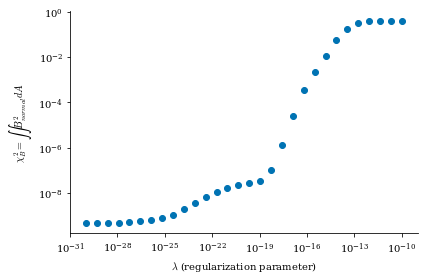

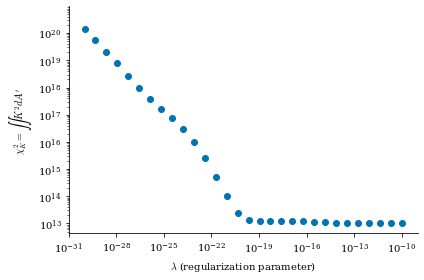

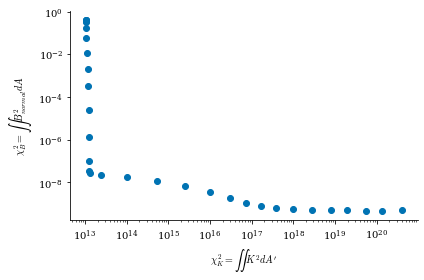

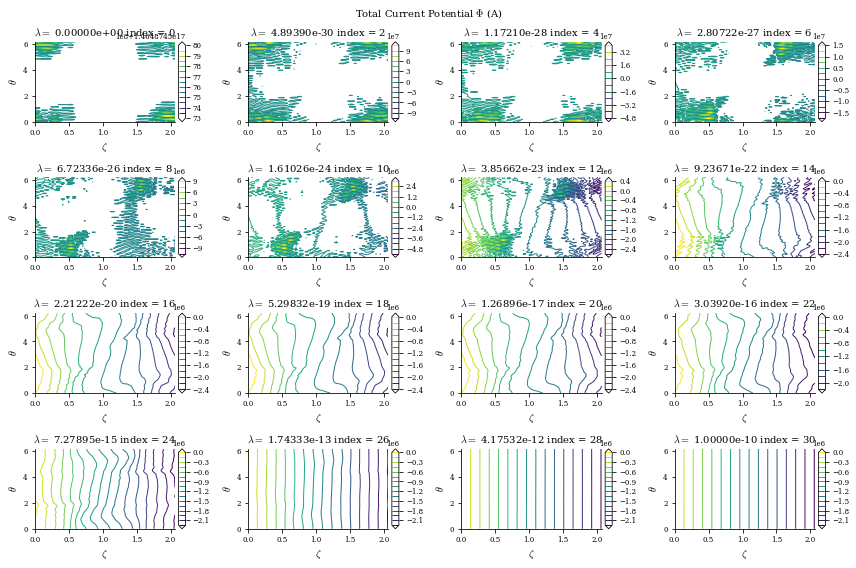

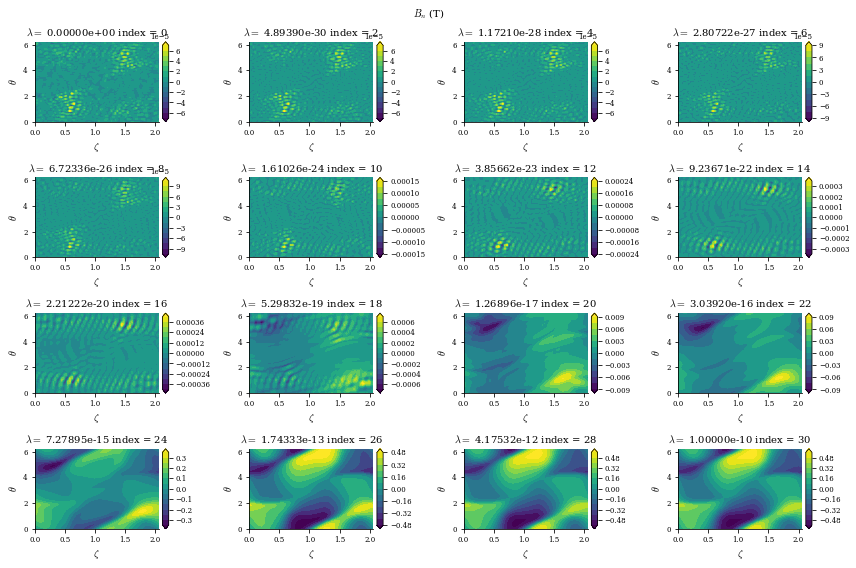

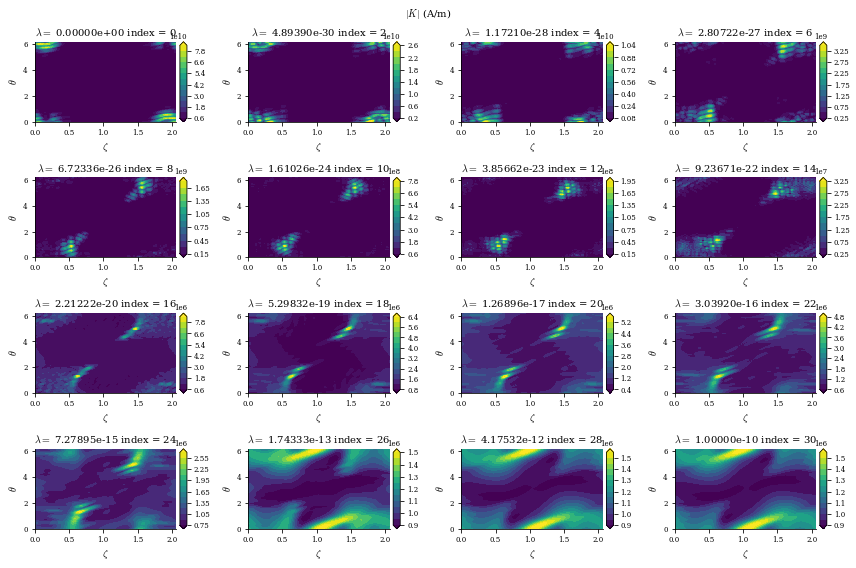

In [31]:
plot_regcoil_outputs(fields,data,eq,vacuum=True)

In [48]:
surface_current_field = fields[21]

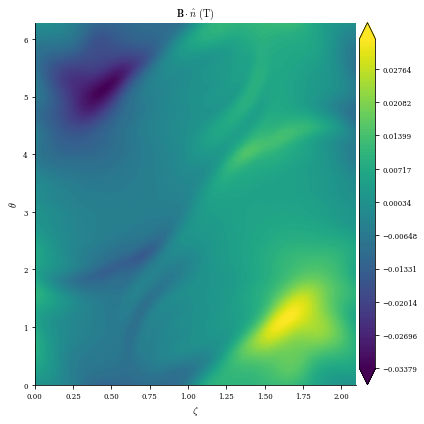

In [49]:
plot_2d(
    eq.surface,
    "B*n",
    field=surface_current_field,
    cmap="viridis",
);

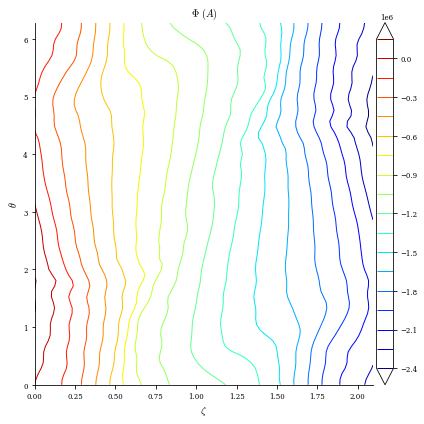

In [50]:
plot_2d(
    surface_current_field, "Phi", filled=False, levels=20
);  # see how the current potential contours look, these are the coil shapes on the surface

In [51]:
# #plot_field_lines(surface_current_field, eq);
# grid_trace = LinearGrid(rho=np.linspace(0, 1, 10))
# r0 = eq.compute("R", grid=grid_trace)["R"]
# z0 = eq.compute("Z", grid=grid_trace)["Z"]
# print(r0)
# fig, ax = desc.plotting.plot_surfaces(eq, figsize=(40, 40))
# fig, ax, data = desc.plotting.poincare_plot(
#     surface_current_field,
#     r0,
#     z0,
#     ntransit=100,
#     NFP=eq.NFP,
#     ax=ax,
#     color="k",
#     size=1,
#     #phi = np.array([0.]),
#     return_data = True,
#     bounds_R = (0.55, 1.6),
#     bounds_Z = (-0.9, 0.9)
# )


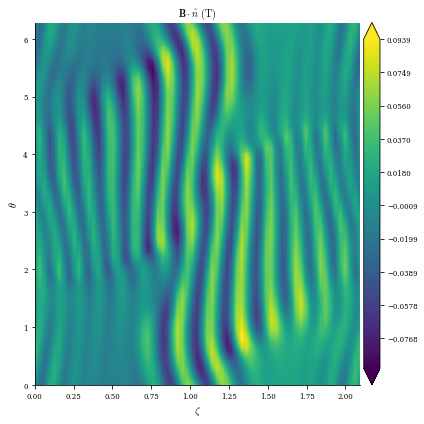

In [52]:
coilset_initial_from_regcoil = surface_current_field.to_CoilSet(
    num_coils=7, stell_sym=True
)
plot_grid = LinearGrid(M=20, N=40, NFP=1, endpoint=True)

coil_grid = LinearGrid(N=60)
plot_2d(
    eq.surface,
    "B*n",
    field=coilset_initial_from_regcoil,
    cmap="viridis",
)
fig =plot_3d(
    eq.surface,
    "B*n",
    field=coilset_initial_from_regcoil,
    field_grid=coil_grid,
    grid=plot_grid,
)

fig = plot_coils(coilset_initial_from_regcoil, fig=fig)
fig.show()

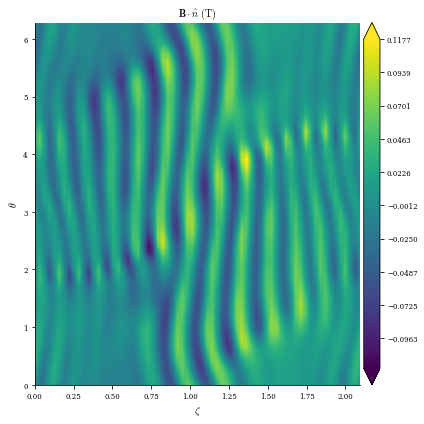

In [53]:
coilset_initial_from_regcoil = coilset_initial_from_regcoil.to_FourierXYZ(N=5)
#coilset_initial_from_regcoil = coilset_initial_from_regcoil.to_FourierXYZ(N=5)
plot_2d(
    eq.surface,
    "B*n",
    field=coilset_initial_from_regcoil,
    cmap="viridis",
)
fig = plot_3d(
    eq.surface,
    "B*n",
    field=coilset_initial_from_regcoil,
    field_grid=coil_grid,
    grid=plot_grid,
)

fig = plot_coils(coilset_initial_from_regcoil, fig=fig)
fig.show()


In [54]:

# fig, ax = desc.plotting.plot_surfaces(eq, figsize=(40, 40))
# fig, ax, data = desc.plotting.poincare_plot(
#     coilset_initial_from_regcoil,
#     r0,
#     z0,
#     ntransit=500,
#     NFP=eq.NFP,
#     ax=ax,
#     color="k",
#     size=1,
#     #phi = np.array([0.]),
#     return_data = True,
#     bounds_R = (0.60, 1.4),
#     bounds_Z = (-0.4, 0.4)
# )

In [55]:
#coilset_initial_from_regcoil.save("NFP3_coilset_72.h5")

/pscratch/sd/r/rgaur/DESC2/DESC/desc/utils.py:572: UserWarning:

Unequal number of field periods for grid 1 and basis 3.

/pscratch/sd/r/rgaur/DESC2/DESC/desc/utils.py:572: UserWarning:

Unequal number of field periods for grid 1 and basis 3.



Building objective: Quadratic flux
Precomputing transforms
Timer: Precomputing transforms = 68.2 ms
Building objective: coil-coil minimum distance
Building objective: plasma-coil minimum distance
Building objective: coil curvature
Precomputing transforms
Timer: Precomputing transforms = 7.53 ms
Building objective: coil length
Precomputing transforms
Timer: Precomputing transforms = 5.41 ms
Timer: Objective build = 503 ms
Building objective: summed coil current
Building objective: fixed shift
Building objective: fixed rotation
Timer: Objective build = 112 ms
Timer: LinearConstraintProjection build = 3.41 sec
Number of parameters: 237
Number of objectives: 7994
Timer: Initializing the optimization = 4.14 sec

Starting optimization
Using method: sgd
Solver options:
----------------------------------------
Alpha          : 4.338e-11
Beta           : 9.000e-01
---------------------------------------- 

   Iteration     Total nfev        Cost      Cost reduction    Step norm     Optimality  

/pscratch/sd/r/rgaur/DESC2/DESC/desc/utils.py:572: UserWarning:

Found coils which are nearly intersecting according to the given grid it is recommended to check coils closely or run function again with a higher resolution grid. Offending coil indices are {8, 9, 4, 5}.

/pscratch/sd/r/rgaur/DESC2/DESC/desc/utils.py:572: UserWarning:

Found coils which are nearly intersecting according to the given grid it is recommended to check coils closely or run function again with a higher resolution grid. Offending coil indices are {8, 9, 4, 5}.



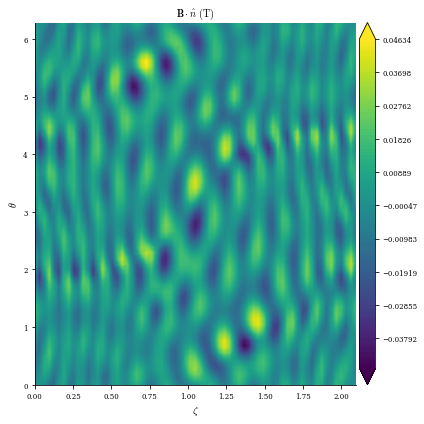

In [56]:
coilset_initial_from_regcoil2 = coilset_initial_from_regcoil.copy()
# number of points used to discretize coils. This could be different for each objective
# (eg if you want higher resolution for some calculations), but we'll use the same for all of them
coil_grid = LinearGrid(N=40)
# similarly define a grid on the plasma surface where B*n errors will be evaluated
plasma_grid = LinearGrid(M=55, N=65, NFP=eq.NFP, sym=eq.sym)


weights = {"quadratic flux": 200,
    "coil-coil min dist": 100,
    "plasma-coil min dist": 10,
    "coil curvature": 300,
    "coil length": 200,
}

def make_vac_coil_obj(eq, coilset, weights_dict):
    obj = ObjectiveFunction(
        (
            QuadraticFlux(
                eq,
                field=coilset,
                # grid of points on plasma surface to evaluate normal field error
                eval_grid=plasma_grid,
                #field_grid=coil_grid,
                vacuum=True,  # vacuum=True means we won't calculate the plasma contribution to B as it is zero
                weight=weights_dict["quadratic flux"],
                bs_chunk_size=10,
            ),
            CoilSetMinDistance(
                coilset,
                # in normalized units, want coil-coil distance to be at least 10% of minor radius
                bounds=(0.2, np.inf),
                normalize_target=False,  # we're giving bounds in normalized units
                grid=coil_grid,
                weight=weights_dict["coil-coil min dist"],
                dist_chunk_size=2,  # this helps to reduce peak memory usage, needed to run on github CI
            ),
            PlasmaCoilSetMinDistance(
                eq,
                coilset,
                # in normalized units, want plasma-coil distance to be at least 25% of minor radius
                bounds=(0.1, np.inf),
                normalize_target=False,  # we're giving bounds in normalized units
                plasma_grid=plasma_grid,
                coil_grid=coil_grid,
                eq_fixed=True,  # Fix the equilibrium. For single stage optimization, this would be False
                weight=weights_dict["plasma-coil min dist"],
                dist_chunk_size=2,  # this helps to reduce peak memory usage, needed to run on github CI
            ),
            CoilCurvature(
                coilset,
                # this uses signed curvature, depending on whether it curves towards
                # or away from the centroid of the curve, with a circle having positive curvature.
                # We give the bounds normalized units, curvature of approx 1 means circular,
                # so we allow them to be a bit more strongly shaped
                bounds=(-20, 20),
                normalize_target=False,  # we're giving bounds in normalized units
                grid=coil_grid,
                weight=weights_dict["coil curvature"],
            ),
            CoilLength(
                coilset,
                bounds=(0, 2.5),
                normalize_target=True,  # target length is in meters, not normalized
                grid=coil_grid,
                weight=weights_dict["coil length"],
            ),
        )
    )
    return obj

grid_at_surf = LinearGrid(rho=1.0, M=eq.M_grid, N=eq.N_grid)
G_tot = 2*np.pi*eq.compute("G", grid=grid_at_surf)["G"][0] / mu_0


obj = make_vac_coil_obj(eq, coilset_initial_from_regcoil2, weights)
constraints = (
    FixSumCoilCurrent(coilset_initial_from_regcoil2,target = G_tot),

)

# Pick an optimizer. For this problem with only linear constraints we can use a regular least squares method.
# if we used the ToroidalFlux constraint we would need to use a constrained optimization method
#optimizer = Optimizer("lsq-exact")
optimizer = Optimizer("sgd")


(optimized_coilset_initial_from_regcoil2,), _ = optimizer.optimize(
    coilset_initial_from_regcoil2,
    objective=obj,
    constraints=constraints,
    maxiter=1000,
    verbose=3,
    copy=True,
    ftol=1e-4,
    #options={"alpha":5e-11, "beta":1.2e0}
)

plot_grid = LinearGrid(M=20, N=40, NFP=1, endpoint=True)
plot_2d(
    eq.surface,
    "B*n",
    field=optimized_coilset_initial_from_regcoil2,
    cmap="viridis",
)
fig = plot_3d(
    eq.surface,
    "B*n",
    field=optimized_coilset_initial_from_regcoil2,
    #field_grid=coil_grid,
    grid=plot_grid,
)

fig = plot_coils(optimized_coilset_initial_from_regcoil2, fig=fig)
fig.show()

In [65]:
coil_grid = LinearGrid(N=40)
# similarly define a grid on the plasma surface where B*n errors will be evaluated
plasma_grid = LinearGrid(M=55, N=65, NFP=eq.NFP, sym=eq.sym)


weights = {"quadratic flux": 200,
    "coil-coil min dist": 100,
    "plasma-coil min dist": 10,
    "coil curvature": 100,
    "coil length": 200,
}

def make_vac_coil_obj(eq, coilset, weights_dict):
    obj = ObjectiveFunction(
        (
            QuadraticFlux(
                eq,
                field=coilset,
                # grid of points on plasma surface to evaluate normal field error
                eval_grid=plasma_grid,
                #field_grid=coil_grid,
                vacuum=True,  # vacuum=True means we won't calculate the plasma contribution to B as it is zero
                weight=weights_dict["quadratic flux"],
                bs_chunk_size=10,
            ),
            CoilSetMinDistance(
                coilset,
                # in normalized units, want coil-coil distance to be at least 10% of minor radius
                bounds=(0.24, np.inf),
                normalize_target=False,  # we're giving bounds in normalized units
                grid=coil_grid,
                weight=weights_dict["coil-coil min dist"],
                dist_chunk_size=2,  # this helps to reduce peak memory usage, needed to run on github CI
            ),
            PlasmaCoilSetMinDistance(
                eq,
                coilset,
                # in normalized units, want plasma-coil distance to be at least 25% of minor radius
                bounds=(0.1, np.inf),
                normalize_target=False,  # we're giving bounds in normalized units
                plasma_grid=plasma_grid,
                coil_grid=coil_grid,
                eq_fixed=True,  # Fix the equilibrium. For single stage optimization, this would be False
                weight=weights_dict["plasma-coil min dist"],
                dist_chunk_size=2,  # this helps to reduce peak memory usage, needed to run on github CI
            ),
            CoilCurvature(
                coilset,
                # this uses signed curvature, depending on whether it curves towards
                # or away from the centroid of the curve, with a circle having positive curvature.
                # We give the bounds normalized units, curvature of approx 1 means circular,
                # so we allow them to be a bit more strongly shaped
                bounds=(-20, 20),
                normalize_target=False,  # we're giving bounds in normalized units
                grid=coil_grid,
                weight=weights_dict["coil curvature"],
            ),
            CoilLength(
                coilset,
                bounds=(0, 2.1),
                normalize_target=True,  # target length is in meters, not normalized
                grid=coil_grid,
                weight=weights_dict["coil length"],
            ),
        )
    )
    return obj

coilset_initial_from_regcoil = optimized_coilset_initial_from_regcoil2.copy()
obj = make_vac_coil_obj(eq, coilset_initial_from_regcoil, weights)
constraints = (
    FixSumCoilCurrent(coilset_initial_from_regcoil,target = G_tot),

)

# Pick an optimizer. For this problem with only linear constraints we can use a regular least squares method.
# if we used the ToroidalFlux constraint we would need to use a constrained optimization method
optimizer = Optimizer("lsq-exact")
#optimizer = Optimizer("sgd")


(optimized_coilset_initial_from_regcoil3,), _ = optimizer.optimize(
    coilset_initial_from_regcoil,
    objective=obj,
    constraints=constraints,
    maxiter=800,
    verbose=3,
    copy=True,
    ftol=1e-4,
    #options={"alpha":5e-11, "beta":1.2e0}
)

Building objective: Quadratic flux
Precomputing transforms
Timer: Precomputing transforms = 70.4 ms
Building objective: coil-coil minimum distance
Building objective: plasma-coil minimum distance
Building objective: coil curvature
Precomputing transforms
Timer: Precomputing transforms = 7.58 ms
Building objective: coil length
Precomputing transforms
Timer: Precomputing transforms = 5.41 ms
Timer: Objective build = 500 ms
Building objective: summed coil current
Building objective: fixed shift
Building objective: fixed rotation
Timer: Objective build = 111 ms
Timer: LinearConstraintProjection build = 129 ms
Number of parameters: 237
Number of objectives: 7994
Timer: Initializing the optimization = 762 ms

Starting optimization
Using method: lsq-exact
Solver options:
------------------------------------------------------------
Maximum Function Evaluations       : 4001
Maximum Allowed Total Δx Norm      : inf
Scaled Termination                 : True
Trust Region Method                : qr

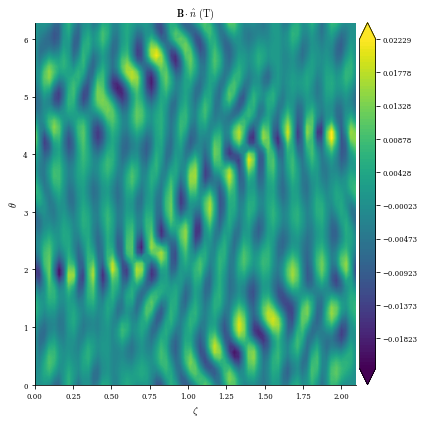

In [66]:
plot_grid = LinearGrid(M=20, N=40, NFP=1, endpoint=True)
plot_2d(
    eq.surface,
    "B*n",
    field=optimized_coilset_initial_from_regcoil3,
    cmap="viridis",
)
fig = plot_3d(
    eq.surface,
    "B*n",
    field=optimized_coilset_initial_from_regcoil3,
    #field_grid=coil_grid,
    grid=plot_grid,
)

fig = plot_coils(optimized_coilset_initial_from_regcoil3, fig=fig)
fig.show()

[1.01979672 1.01470489 1.00956397 1.00437406 0.99912918 0.99381558
 0.98841237 0.98289712 0.97726089 0.97153822]


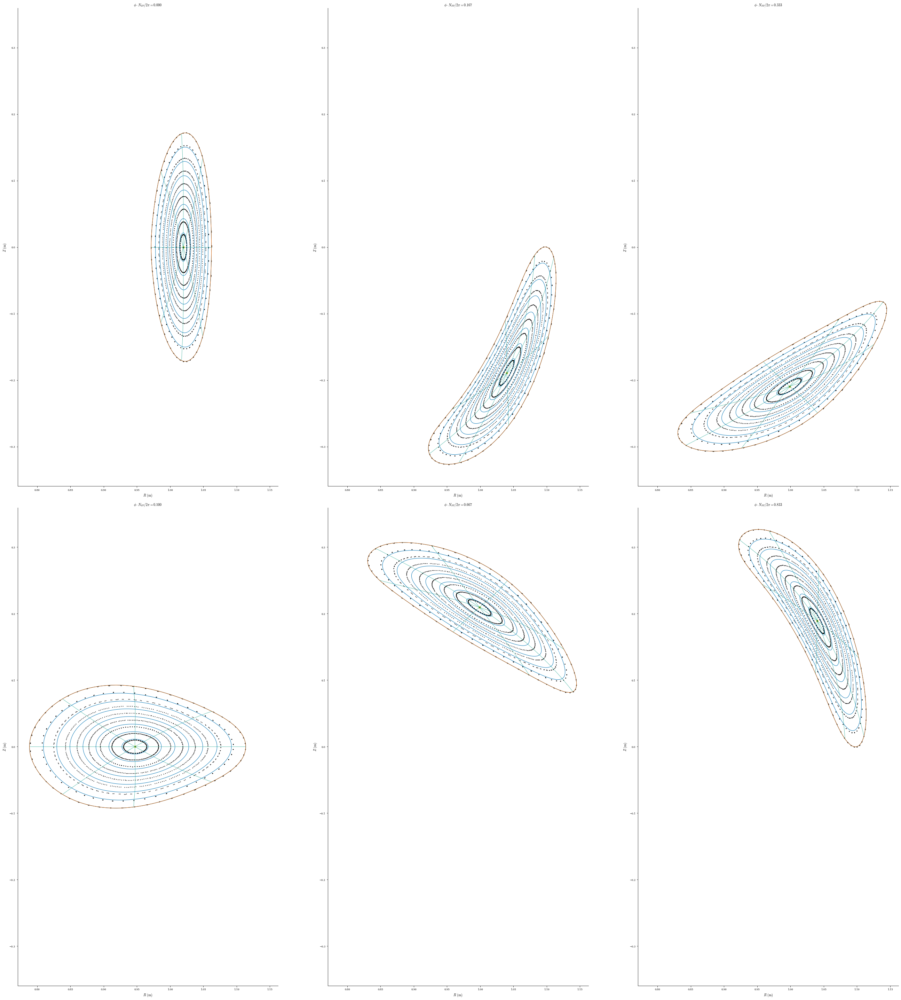

In [68]:
#plot_field_lines(surface_current_field, eq);
grid_trace = LinearGrid(rho=np.linspace(0, 1, 10))
r0 = eq.compute("R", grid=grid_trace)["R"]
z0 = eq.compute("Z", grid=grid_trace)["Z"]
print(r0)
fig, ax = desc.plotting.plot_surfaces(eq, figsize=(40, 40))
fig, ax, data = desc.plotting.poincare_plot(
    optimized_coilset_initial_from_regcoil3,
    r0,
    z0,
    ntransit=200,
    NFP=eq.NFP,
    ax=ax,
    color="k",
    size=1,
    #phi = np.array([0.]),
    return_data = True,
    bounds_R = (0.55, 1.6),
    bounds_Z = (-1, 1)
)

In [69]:
optimized_coilset_initial_from_regcoil3.save("NFP3_coilset_42_coils_smoother_Bn_0p02_N5.h5")